# JagaDia - 02. Spatial Hotspot Clustering (DBSCAN)

**Mata Kuliah:** Machine Learning (COMP657701)
**Sesi Acuan:** Session 19-20 (Clustering Analysis: Density-Based Clustering - DBSCAN)

---

### Tujuan Notebook Ini:
1. Menerapkan algoritma **DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*)** pada koordinat spasial (`lat`, `lon`) data kerawanan Jakarta.
2. Menentukan nilai parameter optimal $\varepsilon$ (*Epsilon*) dan $\text{MinPts}$ menggunakan **K-Distance Graph / Elbow Method** (sesuai Slide 38).
3. Mengelompokkan titik menjadi **Core Points**, **Border Points**, dan memisahkan **Noise Points** (sesuai Slide 33-35).
4. Melakukan profiling cluster hotspot (menghitung centroid, radius aman, jenis kejahatan dominan, dan skor risiko kerawanan).
5. Menghasilkan visualisasi interaktif peta Jakarta (Folium) dan mengekspor zona bahaya ke format **GeoJSON (`risk_zones.json`)** yang siap dikonsumsi oleh aplikasi mobile Android JagaDia.

In [1]:
import sys
from pathlib import Path

# Tambahkan direktori root ML ke path modul
ml_root = Path.cwd().parent
if str(ml_root) not in sys.path:
    sys.path.append(str(ml_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap, MarkerCluster

from src.clustering import (
    compute_k_distances,
    fit_spatial_dbscan,
    summarize_clusters,
    export_risk_zones_geojson,
    EARTH_RADIUS_METERS,
)

print("Setup berhasil! Library dan modul clustering siap digunakan.")

Setup berhasil! Library dan modul clustering siap digunakan.


## 1. Load Data Bersih Hasil Preprocessing
Kita memuat dataset `data_bersih.csv` yang sebelumnya telah dibersihkan dari anomali koordinat dan distandarisasi.

In [2]:
data_path = ml_root / "data" / "processed" / "data_bersih.csv"
df = pd.read_csv(data_path)

print(f"Total data titik kerawanan: {len(df)} baris")
display(df.head())

Total data titik kerawanan: 1007 baris


,wilayah,kecamatan,kelurahan,lat,lon,jenis_rawan,jenis_gabung
0,KOTA ADM. JAKARTA PUSAT,GAMBIR,DURI PULO,-6.170529,106.819195,PENGEMIS,PENGEMIS
1,KOTA ADM. JAKARTA PUSAT,GAMBIR,DURI PULO,-6.170492,106.819266,PKL,PKL
2,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI SELATAN,-6.160866,106.802437,TAWURAN (WARGA / PELAJAR),TAWURAN (WARGA / PELAJAR)
3,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI SELATAN,-6.159615,106.804436,TAWURAN (WARGA / PELAJAR),TAWURAN (WARGA / PELAJAR)
4,KOTA ADM. JAKARTA BARAT,TAMBORA,DURI UTARA,-6.155287,106.801734,PKL,PKL


## 2. Penentuan Epsilon ($\varepsilon$) Menggunakan K-Distance Graph (Elbow Method)
> **Teori Sesi 19-20 Slide 38:**
> Titik-titik di dalam suatu cluster memiliki jarak ke tetangga ke-$k$ (*kth-nearest neighbor*) yang relatif dekat dan seragam, sedangkan titik *noise* memiliki jarak ke tetangga ke-$k$ yang jauh lebih lebar. 
> Dengan mem-plot grafik jarak ke tetangga ke-$k$ yang diurutkan, titik tekukan (*elbow/knee point*) adalah indikasi terbaik untuk nilai $\varepsilon$.

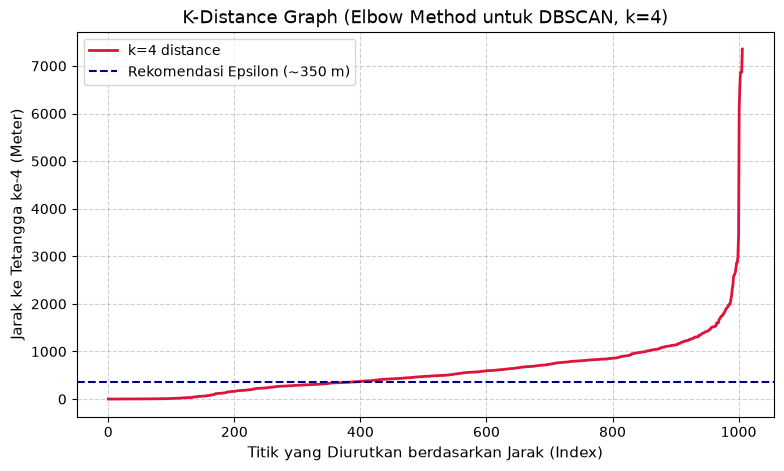

Median jarak ke tetangga ke-4 : 476.2 meter
Persentil 80%                : 863.7 meter


In [3]:
K_NEIGHBORS = 4
sorted_distances = compute_k_distances(df["lat"].values, df["lon"].values, k=K_NEIGHBORS)

plt.figure(figsize=(9, 5))
plt.plot(sorted_distances, color="crimson", linewidth=2, label=f"k={K_NEIGHBORS} distance")
plt.axhline(y=350, color="navy", linestyle="--", label="Rekomendasi Epsilon (~350 m)")
plt.title(f"K-Distance Graph (Elbow Method untuk DBSCAN, k={K_NEIGHBORS})", fontsize=13)
plt.xlabel("Titik yang Diurutkan berdasarkan Jarak (Index)", fontsize=11)
plt.ylabel("Jarak ke Tetangga ke-4 (Meter)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.show()

p50 = np.percentile(sorted_distances, 50)
p80 = np.percentile(sorted_distances, 80)
print(f"Median jarak ke tetangga ke-4 : {p50:.1f} meter")
print(f"Persentil 80%                : {p80:.1f} meter")

## 3. Training Spatial DBSCAN dengan Metrik Haversine
Kita melatih model DBSCAN dengan:
- **Epsilon ($\varepsilon$):** `350 meter` (sekitar radius 1-2 blok persimpangan jalan di Jakarta).
- **MinPts:** `4 titik` (minimal terdapat 4 laporan/insiden dalam radius 350m untuk dianggap sebagai sarang hotspot).

In [4]:
EPS_METERS = 350.0
MIN_SAMPLES = 4

df_clustered, db_model = fit_spatial_dbscan(
    df, lat_col="lat", lon_col="lon", eps_meters=EPS_METERS, min_samples=MIN_SAMPLES
)

n_clusters = len(set(df_clustered["cluster_id"])) - (1 if -1 in df_clustered["cluster_id"] else 0)
n_noise = (df_clustered["cluster_id"] == -1).sum()
n_core = (df_clustered["point_type"] == "core").sum()
n_border = (df_clustered["point_type"] == "border").sum()

print("=" * 45)
print("HASIL CLUSTERING DBSCAN SPASIAL")
print("=" * 45)
print(f"Jumlah Cluster Terbentuk : {n_clusters} cluster hotspot")
print(f"Jumlah Core Points       : {n_core} titik")
print(f"Jumlah Border Points     : {n_border} titik")
print(f"Jumlah Noise (Pencilan)  : {n_noise} titik ({n_noise/len(df)*100:.1f}%)")

HASIL CLUSTERING DBSCAN SPASIAL
Jumlah Cluster Terbentuk : 63 cluster hotspot
Jumlah Core Points       : 377 titik
Jumlah Border Points     : 74 titik
Jumlah Noise (Pencilan)  : 556 titik (55.2%)


## 4. Profiling & Perhitungan Skor Risiko Hotspot
Untuk setiap cluster, kita hitung:
- **Centroid** (koordinat pusat hotspot)
- **Radius Buffer (meter)**
- **Jenis Kerawanan Dominan**
- **Skor Risiko / Risk Score $[0.0, 1.0]$** (berdasarkan bobot kejahatan kekerasan seperti tawuran/kriminalitas vs parkir liar/pkl)

In [5]:
cluster_summary = summarize_clusters(df_clustered, lat_col="lat", lon_col="lon", crime_col="jenis_gabung")

print(f"Top 10 Cluster Paling Rawan (dari total {len(cluster_summary)} cluster):")
display(cluster_summary.head(10))

# Simpan ringkasan cluster ke CSV
summary_csv = ml_root / "data" / "processed" / "cluster_hotspots_summary.csv"
cluster_summary.to_csv(summary_csv, index=False)
print(f"Ringkasan cluster tersimpan di: {summary_csv}")

Top 10 Cluster Paling Rawan (dari total 62 cluster):


,cluster_id,centroid_lat,centroid_lon,radius_meters,incident_count,core_points,border_points,top_incident,risk_score,wilayah,kecamatan,kelurahan
0,1,-6.175199,106.865153,150.0,5,5,0,TAWURAN (WARGA / PELAJAR),0.90,KOTA ADM. JAKARTA PUSAT,JOHAR BARU,GALUR
1,26,-6.186008,106.887442,150.0,8,8,0,KRIMINALITAS,0.82,KOTA ADM. JAKARTA TIMUR,PULOGADUNG,KAYU PUTIH
2,15,-6.171970,106.860316,356.2,4,1,3,KRIMINALITAS,0.82,KOTA ADM. JAKARTA PUSAT,JOHAR BARU,CEMPAKA BARU
3,20,-6.098122,106.714188,150.0,4,4,0,PAK OGAH,0.79,KOTA ADM. JAKARTA UTARA,PENJARINGAN,KAMAL MUARA
4,30,-6.205624,106.855666,150.0,4,4,0,KRIMINALITAS,0.79,KOTA ADM. JAKARTA TIMUR,MATRAMAN,KEBON MANGGIS
5,14,-6.168420,106.831595,302.9,4,2,2,PARKIR LIAR,0.77,KOTA ADM. JAKARTA PUSAT,SAWAH BESAR,PASAR BARU
6,24,-6.155369,106.830617,420.7,8,5,3,PKL,0.76,KOTA ADM. JAKARTA PUSAT,SAWAH BESAR,KARTINI
7,25,-6.204104,106.820252,541.3,7,5,2,TAWURAN (WARGA / PELAJAR),0.75,KOTA ADM. JAKARTA PUSAT,TANAH ABANG,KARET TENGSIN
8,56,-6.302136,106.872026,150.0,5,5,0,TAWURAN (WARGA / PELAJAR),0.75,KOTA ADM. JAKARTA TIMUR,CIRACAS,RAMBUTAN
9,58,-6.215262,106.939385,563.8,8,4,4,PARKIR LIAR,0.73,KOTA ADM. JAKARTA TIMUR,CAKUNG,PENGGILINGAN


Ringkasan cluster tersimpan di: d:\PPTI\Cawu 4 Projects\JagaDia\ML\data\processed\cluster_hotspots_summary.csv


## 5. Visualisasi Spasial Sebaran Cluster Hotspot
Menampilkan visualisasi sebaran Core, Border, dan Noise points.

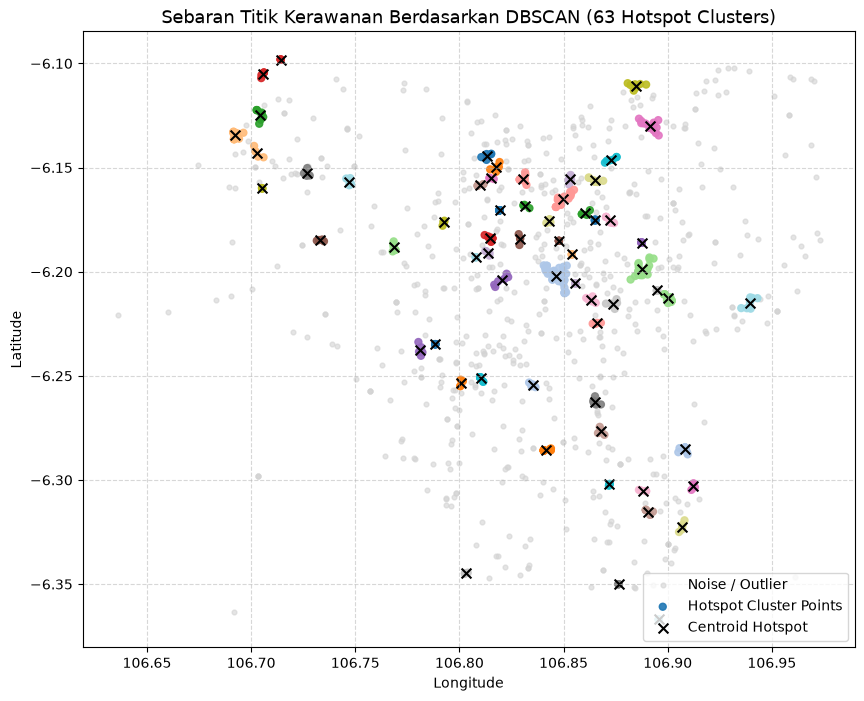

In [6]:
plt.figure(figsize=(10, 8))

# Plot noise points (abu-abu pudar)
noise = df_clustered[df_clustered["cluster_id"] == -1]
plt.scatter(noise["lon"], noise["lat"], c="lightgray", s=12, label="Noise / Outlier", alpha=0.6)

# Plot clustered points dengan warna sesuai cluster
clustered = df_clustered[df_clustered["cluster_id"] != -1]
scatter = plt.scatter(
    clustered["lon"],
    clustered["lat"],
    c=clustered["cluster_id"],
    cmap="tab20",
    s=25,
    alpha=0.9,
    label="Hotspot Cluster Points",
)

# Plot Centroids
plt.scatter(
    cluster_summary["centroid_lon"],
    cluster_summary["centroid_lat"],
    c="black",
    marker="x",
    s=50,
    label="Centroid Hotspot",
)

plt.title(f"Sebaran Titik Kerawanan Berdasarkan DBSCAN ({n_clusters} Hotspot Clusters)", fontsize=13)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.gca().set_aspect("equal")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 6. Peta Interaktif Jakarta (Folium Map)
Membuat peta interaktif dengan lingkaran zona bahaya (*buffer circle*) berwarna merah transparan sesuai skor kerawanan.

In [7]:
# Inisialisasi peta berpusat di Jakarta
m = folium.Map(location=[-6.2088, 106.8456], zoom_start=11, tiles="CartoDB positron")

# Tambahkan circle zona bahaya untuk setiap cluster
for _, row in cluster_summary.iterrows():
    # Warna berdasarkan risk score
    color = "#d90429" if row["risk_score"] >= 0.7 else "#f77f00" if row["risk_score"] >= 0.4 else "#fcbf49"
    
    popup_html = f"""
    <div style='font-family: sans-serif; width: 200px;'>
        <h4 style='margin:0 0 5px 0; color: #d90429;'>Zona Rawan #{int(row['cluster_id'])}</h4>
        <b>Wilayah:</b> {row['wilayah']}<br>
        <b>Kelurahan:</b> {row['kelurahan']}<br>
        <b>Kejahatan Dominan:</b> {row['top_incident']}<br>
        <b>Jumlah Laporan:</b> {int(row['incident_count'])} kejadian<br>
        <b>Risk Score:</b> <span style='color:red; font-weight:bold;'>{row['risk_score']:.2f}</span><br>
        <b>Radius Bahaya:</b> {row['radius_meters']:.0f} m
    </div>
    """
    
    folium.Circle(
        location=[row["centroid_lat"], row["centroid_lon"]],
        radius=float(row["radius_meters"]),
        color=color,
        weight=2,
        fill=True,
        fill_color=color,
        fill_opacity=0.35,
        popup=folium.Popup(popup_html, max_width=250),
        tooltip=f"Cluster #{int(row['cluster_id'])}: {row['top_incident']} (Risk: {row['risk_score']})",
    ).add_to(m)

# Simpan peta interaktif sebagai HTML
report_dir = ml_root / "reports"
report_dir.mkdir(parents=True, exist_ok=True)
map_path = report_dir / "peta_hotspot_dbscan.html"
m.save(str(map_path))
print(f"Peta interaktif berhasil disimpan di: {map_path}")
m

Peta interaktif berhasil disimpan di: d:\PPTI\Cawu 4 Projects\JagaDia\ML\reports\peta_hotspot_dbscan.html


c:\Users\evanh\anaconda3\envs\JagaDia\Lib\site-packages\folium\raster_layers.py:128: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 7. Ekspor GeoJSON untuk Aplikasi Android Mobile
Data cluster ini diekspor ke format GeoJSON `FeatureCollection` yang sesuai dengan `APP/app/src/main/assets/risk_zones.json` agar tim Mobile dapat langsung memuat zona rawan ini di peta Google Maps / Mapbox.

In [8]:
geojson_output = ml_root / "data" / "processed" / "risk_zones_dbscan.json"
geojson_data = export_risk_zones_geojson(cluster_summary, geojson_output)

print(f"Total features diekspor: {len(geojson_data['features'])}")

# Opsi: Salin langsung ke folder assets aplikasi Android jika diinginkan
android_asset_path = ml_root.parent / "APP" / "app" / "src" / "main" / "assets" / "risk_zones.json"
if android_asset_path.parent.exists():
    with open(android_asset_path, "w", encoding="utf-8") as f:
        import json
        json.dump(geojson_data, f, indent=2)
    print(f"Berhasil disinkronkan ke aset Android: {android_asset_path}")
else:
    print("Folder aset Android belum ditemukan, file tersimpan di ML/data/processed/")

GeoJSON risk zones exported to: d:\PPTI\Cawu 4 Projects\JagaDia\ML\data\processed\risk_zones_dbscan.json (62 clusters)
Total features diekspor: 62
Berhasil disinkronkan ke aset Android: d:\PPTI\Cawu 4 Projects\JagaDia\APP\app\src\main\assets\risk_zones.json


## 8. Kesimpulan & Integrasi ke Tahap 2

1. **DBSCAN Berhasil Mengidentifikasi Pola Spasial:** Pola kejahatan di DKI Jakarta terkelompok secara padat di persimpangan jalan, pasar, dan perbatasan pemukiman padat.
2. **Noise Filtering:** Laporan acak yang terisolasi otomatis dipisahkan sehingga tidak membebani peringatan rute jalan.
3. **Koneksi ke Tahap 2 (Classification):** 
   - Label `cluster_id` dan jarak ke centroid hotspot terdekat dapat digunakan sebagai **fitur spasial baru** (*spatial distance to hotspot*) pada model klasifikasi (Random Forest, SVM, dan Logistic Regression) untuk memprediksi probabilitas kerawanan segmen jalan baru secara real-time.